# Loan Approval Prediction

A Machine Learning project to analyze loan application data and predict whether a loan will be approved or rejected.

**Project Type:** Exploratory Data Analysis (EDA) + Machine Learning

**Tools Used:** Python, Jupyter Notebook, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

## Introduction

Loan approval is an important process in the banking sector. Banks evaluate various factors such as applicant income, credit history, education, and loan amount before approving a loan.

This project uses Exploratory Data Analysis (EDA) and Machine Learning techniques to understand loan application data and predict whether a loan will be approved or rejected.

## Project Objectives

- To understand and analyze loan application data.
- To identify important factors associated with loan approval.
- To perform Exploratory Data Analysis (EDA) using visualizations.
- To preprocess the dataset for Machine Learning.
- To build and evaluate different classification models.
- To identify the best-performing model for loan approval prediction.

## Tools and Technologies Used

- **Programming Language:** Python
- **Environment:** Jupyter Notebook (VS Code)
- **Libraries:** Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn
- **Machine Learning Algorithms:** Logistic Regression, Decision Tree, Random Forest, KNN, SVM

### Importing Libraries

The required Python libraries are imported for data analysis, visualization, preprocessing, and machine learning.

In [76]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Loading the Dataset

The loan prediction dataset is loaded using Pandas for further analysis.

In [77]:
df = pd.read_csv('Loan prediction.csv')

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## Data Understanding

The dataset is explored to understand its structure, dimensions, column names, data types, and statistical summary.

In [78]:
df.shape

(614, 13)

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [80]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [81]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [82]:
for col in df.select_dtypes(include='object').columns:
    print(col, ":", df[col].unique())

Loan_ID : ['LP001002' 'LP001003' 'LP001005' 'LP001006' 'LP001008' 'LP001011'
 'LP001013' 'LP001014' 'LP001018' 'LP001020' 'LP001024' 'LP001027'
 'LP001028' 'LP001029' 'LP001030' 'LP001032' 'LP001034' 'LP001036'
 'LP001038' 'LP001041' 'LP001043' 'LP001046' 'LP001047' 'LP001050'
 'LP001052' 'LP001066' 'LP001068' 'LP001073' 'LP001086' 'LP001087'
 'LP001091' 'LP001095' 'LP001097' 'LP001098' 'LP001100' 'LP001106'
 'LP001109' 'LP001112' 'LP001114' 'LP001116' 'LP001119' 'LP001120'
 'LP001123' 'LP001131' 'LP001136' 'LP001137' 'LP001138' 'LP001144'
 'LP001146' 'LP001151' 'LP001155' 'LP001157' 'LP001164' 'LP001179'
 'LP001186' 'LP001194' 'LP001195' 'LP001197' 'LP001198' 'LP001199'
 'LP001205' 'LP001206' 'LP001207' 'LP001213' 'LP001222' 'LP001225'
 'LP001228' 'LP001233' 'LP001238' 'LP001241' 'LP001243' 'LP001245'
 'LP001248' 'LP001250' 'LP001253' 'LP001255' 'LP001256' 'LP001259'
 'LP001263' 'LP001264' 'LP001265' 'LP001266' 'LP001267' 'LP001273'
 'LP001275' 'LP001279' 'LP001280' 'LP001282' 'LP0012

###  Target Variable Distribution

In this step, we examine the distribution of loan approvals and rejections in the dataset.

In [83]:
df['Loan_Status'].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

In [84]:
df['Loan_Status'].value_counts(normalize=True) * 100

Loan_Status
Y    68.729642
N    31.270358
Name: proportion, dtype: float64

#### Observation

Out of 614 loan applications, 422 applications (68.73%) were approved, while 192 applications (31.27%) were rejected.

The dataset contains more approved applications than rejected applications.

## Data Quality Assessment

The dataset is checked for missing values, duplicate records, unique values, and potential outliers to identify data quality issues.

In [85]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [86]:
df.duplicated().sum()

np.int64(0)

#### Observation

The dataset contains no duplicate records. Therefore, no duplicate removal is required.

In [87]:
df.dtypes

Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object

In [88]:
df.select_dtypes(include=['int64', 'float64']).nunique()

ApplicantIncome      505
CoapplicantIncome    287
LoanAmount           203
Loan_Amount_Term      10
Credit_History         2
dtype: int64

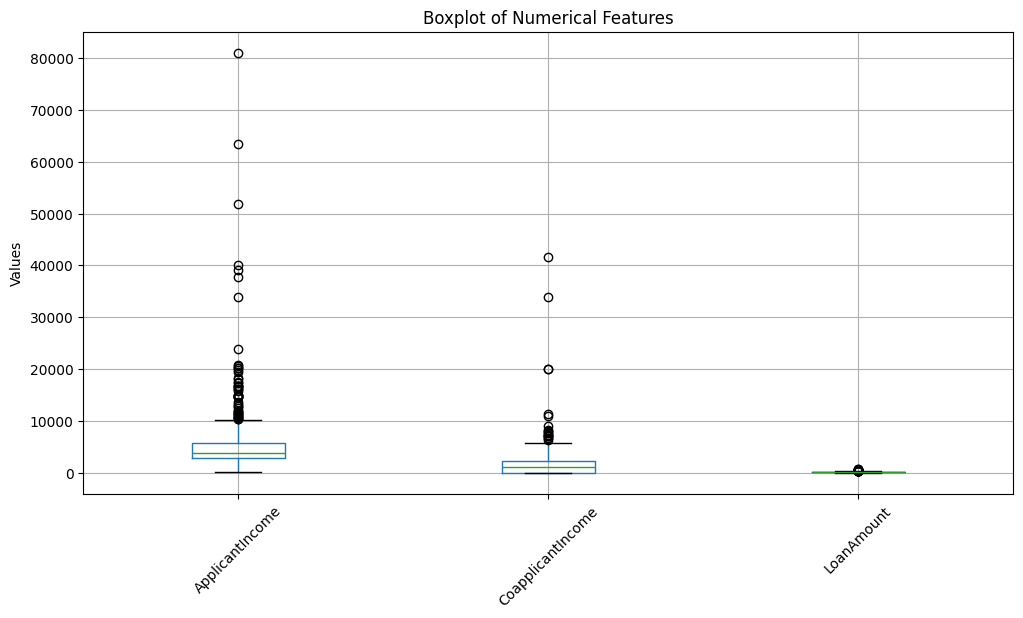

In [89]:
plt.figure(figsize=(12, 6))

df[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']].boxplot()

plt.title('Boxplot of Numerical Features')
plt.ylabel('Values')
plt.xticks(rotation=45)
plt.show()

In [90]:
numerical_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))

ApplicantIncome : 50
CoapplicantIncome : 18
LoanAmount : 39


## Data Cleaning

Missing categorical values are filled using the mode.

In [91]:
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [92]:
numerical_cols = ['LoanAmount', 'Loan_Amount_Term']

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

In [93]:
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

In [94]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [95]:
df.drop('Loan_ID', axis=1, inplace=True)

In [96]:
df.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of loan status and the relationships between different applicant features and loan approval.

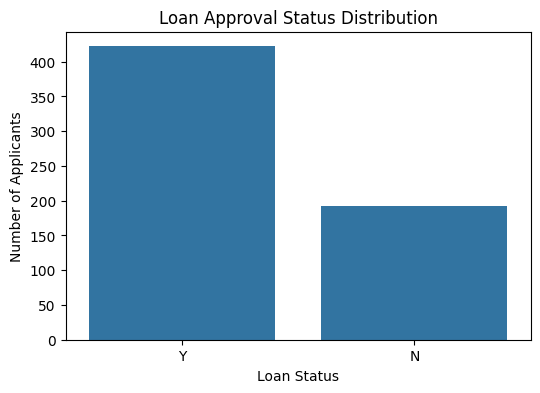

In [97]:
plt.figure(figsize=(6, 4))

sns.countplot(x='Loan_Status', data=df)

plt.title('Loan Approval Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Applicants')
plt.show()

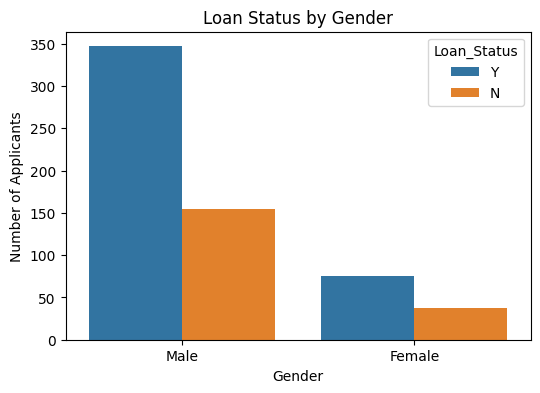

In [98]:
plt.figure(figsize=(6, 4))

sns.countplot(x='Gender', hue='Loan_Status', data=df)

plt.title('Loan Status by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Applicants')
plt.show()

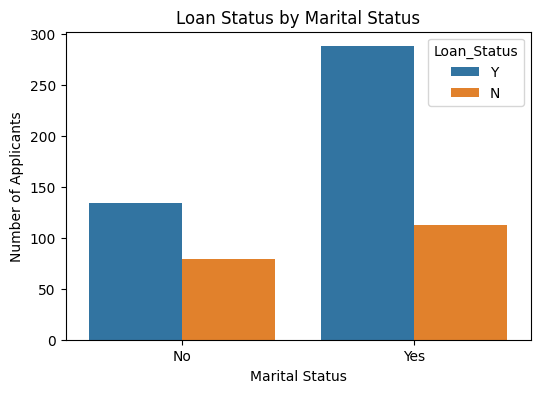

In [99]:
plt.figure(figsize=(6, 4))

sns.countplot(x='Married', hue='Loan_Status', data=df)

plt.title('Loan Status by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Applicants')
plt.show()

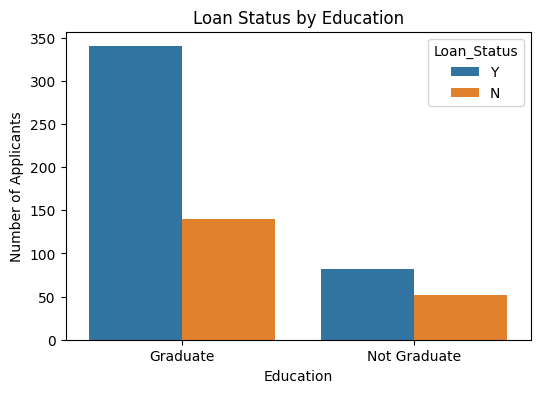

In [100]:
plt.figure(figsize=(6, 4))

sns.countplot(x='Education', hue='Loan_Status', data=df)

plt.title('Loan Status by Education')
plt.xlabel('Education')
plt.ylabel('Number of Applicants')
plt.show()

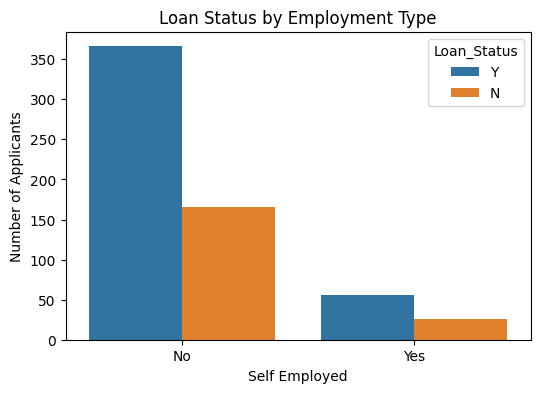

In [101]:
plt.figure(figsize=(6, 4))

sns.countplot(x='Self_Employed', hue='Loan_Status', data=df)

plt.title('Loan Status by Employment Type')
plt.xlabel('Self Employed')
plt.ylabel('Number of Applicants')
plt.show()

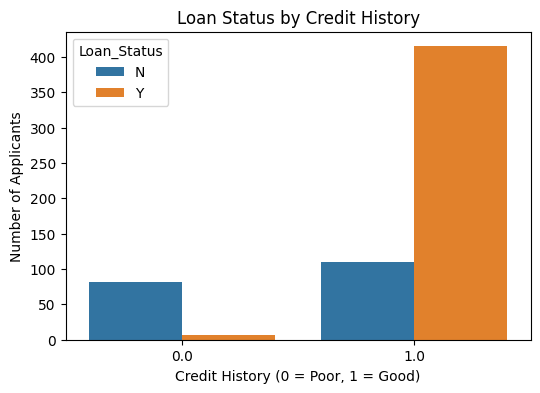

In [102]:
plt.figure(figsize=(6, 4))

sns.countplot(x='Credit_History', hue='Loan_Status', data=df)

plt.title('Loan Status by Credit History')
plt.xlabel('Credit History (0 = Poor, 1 = Good)')
plt.ylabel('Number of Applicants')
plt.show()

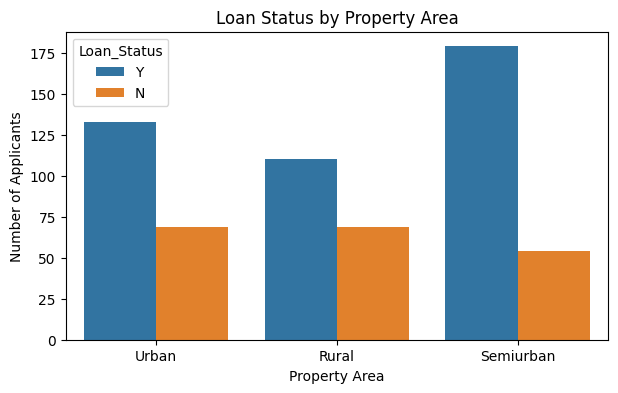

In [103]:
plt.figure(figsize=(7, 4))

sns.countplot(x='Property_Area', hue='Loan_Status', data=df)

plt.title('Loan Status by Property Area')
plt.xlabel('Property Area')
plt.ylabel('Number of Applicants')
plt.show()

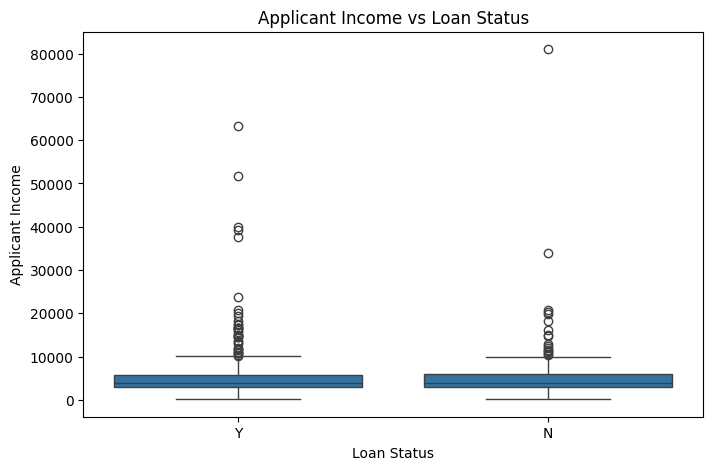

In [104]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Loan_Status', y='ApplicantIncome', data=df)

plt.title('Applicant Income vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Applicant Income')
plt.show()

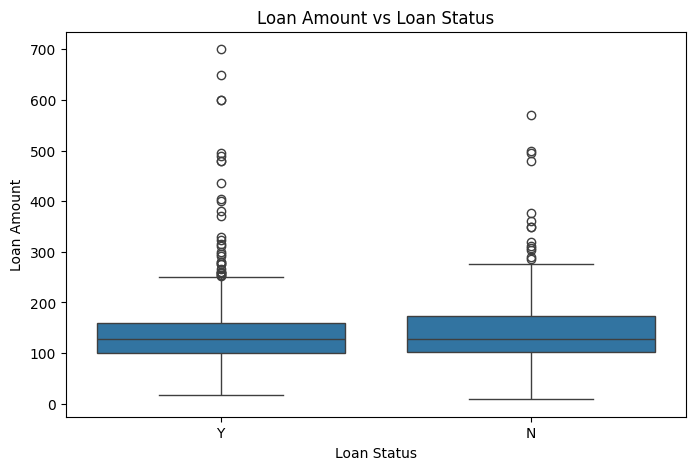

In [105]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Loan_Status', y='LoanAmount', data=df)

plt.title('Loan Amount vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Loan Amount')
plt.show()

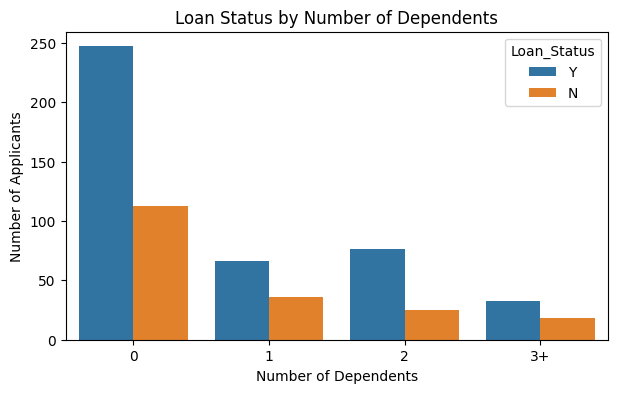

In [106]:
plt.figure(figsize=(7, 4))

sns.countplot(x='Dependents', hue='Loan_Status', data=df)

plt.title('Loan Status by Number of Dependents')
plt.xlabel('Number of Dependents')
plt.ylabel('Number of Applicants')
plt.show()

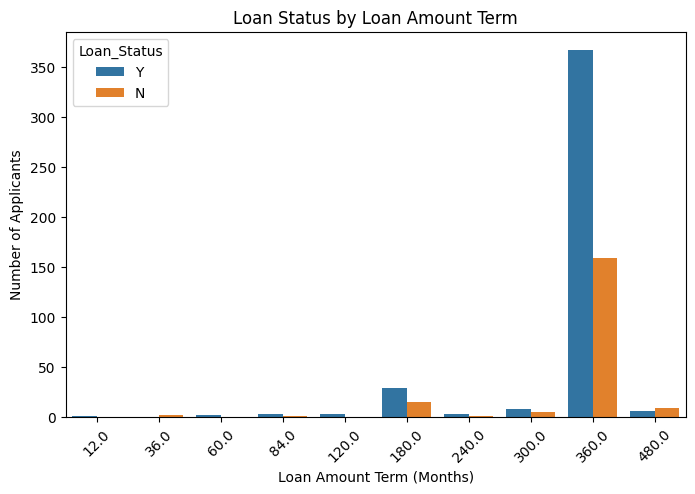

In [107]:
plt.figure(figsize=(8, 5))

sns.countplot(x='Loan_Amount_Term', hue='Loan_Status', data=df)

plt.title('Loan Status by Loan Amount Term')
plt.xlabel('Loan Amount Term (Months)')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45)
plt.show()

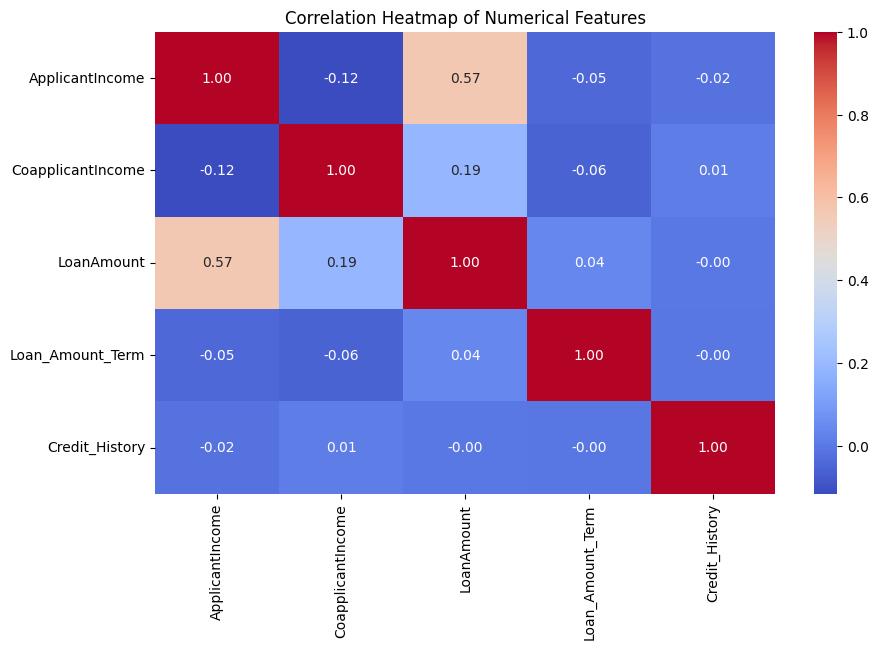

In [108]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include=['int64', 'float64']).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

## Data Preprocessing

The dataset is prepared for Machine Learning by separating features and target variables and splitting the data into training and testing sets.

In [109]:
X = df.drop('Loan_Status', axis=1)

y = df['Loan_Status']

In [110]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (614, 11)
Target shape: (614,)


In [111]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [112]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (491, 11)
X_test: (123, 11)
y_train: (491,)
y_test: (123,)


In [113]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [114]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

X_train.head()

Training Features: (491, 14)
Testing Features: (123, 14)


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
154,3254,0.0,50.0,360.0,1.0,True,False,False,False,False,False,False,False,True
239,3315,0.0,96.0,360.0,1.0,True,True,True,False,False,False,False,True,False
448,3340,1710.0,150.0,360.0,0.0,True,True,False,True,False,False,False,False,False
471,2653,1500.0,113.0,180.0,0.0,True,True,True,False,False,True,False,False,False
273,2620,2223.0,150.0,360.0,1.0,True,True,False,False,False,False,False,True,False


In [115]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

num_cols = ['ApplicantIncome', 'CoapplicantIncome',
            'LoanAmount', 'Loan_Amount_Term']

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

X_test[num_cols] = scaler.transform(X_test[num_cols])

In [116]:
X_train.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
154,-0.352802,-0.563228,-1.131588,0.280691,1.0,True,False,False,False,False,False,False,False,True
239,-0.343346,-0.563228,-0.592309,0.280691,1.0,True,True,True,False,False,False,False,True,False
448,-0.339471,0.050405,0.040758,0.280691,0.0,True,True,False,True,False,False,False,False,False
471,-0.445963,-0.024953,-0.393010,-2.486768,0.0,True,True,True,False,False,True,False,False,False
273,-0.451078,0.234495,0.040758,0.280691,1.0,True,True,False,False,False,False,False,True,False


In [117]:
y_train = y_train.map({'Y': 1, 'N': 0})
y_test = y_test.map({'Y': 1, 'N': 0})

In [118]:
y_train.value_counts()

Loan_Status
1    337
0    154
Name: count, dtype: int64

## 1.Logistic Regression

Logistic Regression is a supervised machine learning classification algorithm used to predict whether a loan application will be approved or rejected based on applicant details.

In [119]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [120]:
y_pred_lr = lr_model.predict(X_test)

In [121]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr * 100, "%")

Logistic Regression Accuracy: 86.1788617886179 %


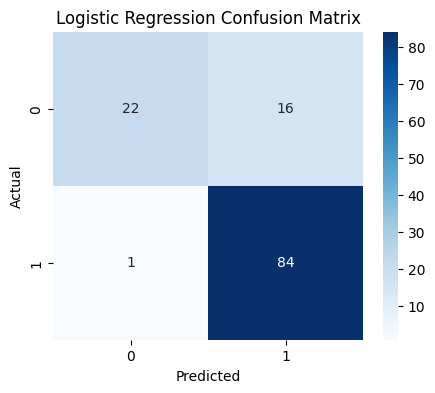

In [122]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [123]:
print("Logistic Regression Classification Report:\n")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



## 2.Decision Tree Classifier

Decision Tree is a supervised machine learning classification algorithm that uses a tree-like structure to make decisions and predict whether a loan application will be approved or rejected.

In [124]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [125]:
y_pred_dt = dt_model.predict(X_test)

In [126]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt * 100, "%")

Decision Tree Accuracy: 71.54471544715447 %


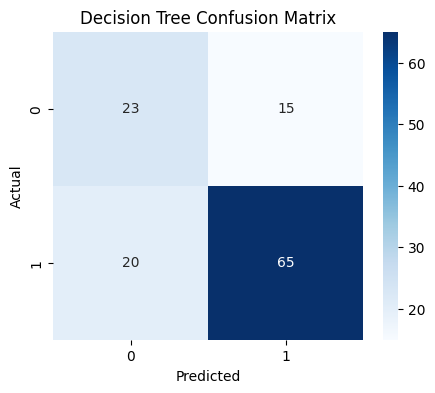

In [127]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues')

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [128]:
print("Decision Tree Classification Report:\n")
print(classification_report(y_test, y_pred_dt))

Decision Tree Classification Report:

              precision    recall  f1-score   support

           0       0.53      0.61      0.57        38
           1       0.81      0.76      0.79        85

    accuracy                           0.72       123
   macro avg       0.67      0.68      0.68       123
weighted avg       0.73      0.72      0.72       123



## 3.Random Forest Classifier

Random Forest is a supervised machine learning classification algorithm that combines multiple decision trees to improve prediction accuracy and reduce overfitting.

In [129]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [130]:
y_pred_rf = rf_model.predict(X_test)

In [131]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf * 100, "%")

Random Forest Accuracy: 83.73983739837398 %


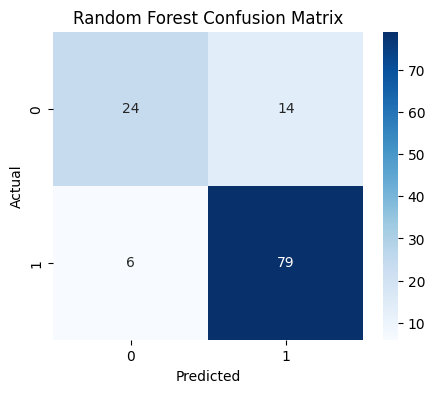

In [132]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [133]:
print("Random Forest Classification Report:\n")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report:

              precision    recall  f1-score   support

           0       0.80      0.63      0.71        38
           1       0.85      0.93      0.89        85

    accuracy                           0.84       123
   macro avg       0.82      0.78      0.80       123
weighted avg       0.83      0.84      0.83       123



## 4.K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised machine learning classification algorithm that predicts the class of a new data point based on the majority class of its nearest neighbors.

In [134]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

KNeighborsClassifier()

In [135]:
y_pred_knn = knn_model.predict(X_test)

In [136]:
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", accuracy_knn * 100, "%")

KNN Accuracy: 81.30081300813008 %


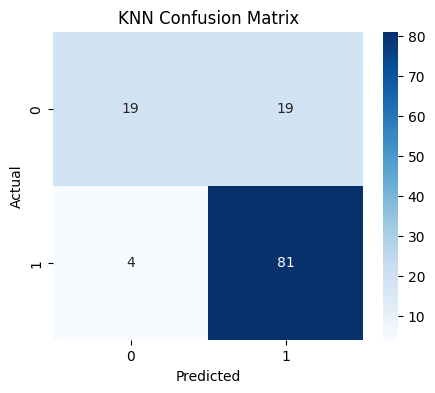

In [137]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues')

plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [138]:
print("KNN Classification Report:\n")
print(classification_report(y_test, y_pred_knn))

KNN Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.50      0.62        38
           1       0.81      0.95      0.88        85

    accuracy                           0.81       123
   macro avg       0.82      0.73      0.75       123
weighted avg       0.81      0.81      0.80       123



## 5.Support Vector Machine (SVM)

Support Vector Machine is a supervised machine learning classification algorithm that finds the optimal boundary (hyperplane) to separate different classes and predict whether a loan application will be approved or rejected.

In [139]:
from sklearn.svm import SVC

svm_model = SVC()

svm_model.fit(X_train, y_train)

SVC()

In [140]:
y_pred_svm = svm_model.predict(X_test)

In [141]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", accuracy_svm * 100, "%")

SVM Accuracy: 84.5528455284553 %


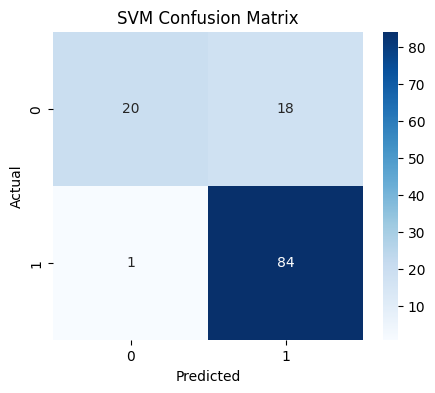

In [142]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues')

plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [143]:
print("SVM Classification Report:\n")
print(classification_report(y_test, y_pred_svm))

SVM Classification Report:

              precision    recall  f1-score   support

           0       0.95      0.53      0.68        38
           1       0.82      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123



## Model Comparison and Evaluation

In [144]:
model_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVM'],
    'Accuracy (%)': [
        accuracy_lr * 100,
        accuracy_dt * 100,
        accuracy_rf * 100,
        accuracy_knn * 100,
        accuracy_svm * 100
    ]
})

model_results.sort_values(by='Accuracy (%)', ascending=False)

,Model,Accuracy (%)
0,Logistic Regression,86.178862
4,SVM,84.552846
2,Random Forest,83.739837
3,KNN,81.300813
1,Decision Tree,71.544715


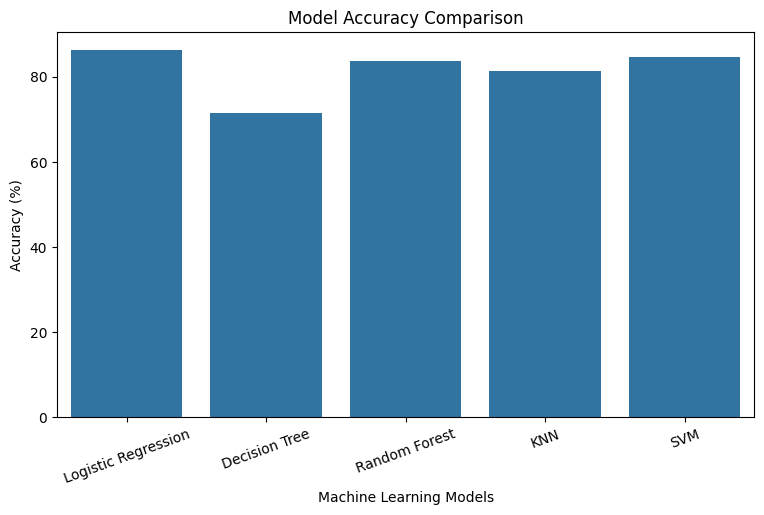

In [145]:
plt.figure(figsize=(9, 5))

sns.barplot(x='Model', y='Accuracy (%)', data=model_results)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=20)

plt.show()

## Best Model Selection

Based on the accuracy comparison, Logistic Regression was selected as the best-performing model with an accuracy of 86.18%.

In [146]:
best_model = LogisticRegression(max_iter=1000)

best_model.fit(X_train, y_train)

y_pred_best = best_model.predict(X_test)

print("Best Model: Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred_best) * 100, "%")

Best Model: Logistic Regression
Accuracy: 86.1788617886179 %


## Conclusion

In this project, Exploratory Data Analysis (EDA) and Machine Learning techniques were used to analyze and predict loan approval status.

Five classification algorithms were implemented: Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors (KNN), and Support Vector Machine (SVM).

Among these models, Logistic Regression achieved the highest accuracy of 86.18%, making it the best-performing model based on accuracy.

The analysis also showed that model performance differs between approved and rejected loan applications. Therefore, precision, recall, and F1-score were considered along with accuracy.

This project demonstrates how machine learning can support loan approval prediction using applicant information.